# Position-mix regression: [Defender, Midfielder, Attacker] (multi-position aware)
Each player gets a target vector summing to 1: `DF`→[1,0,0], `MF`→[0,1,0], `FW`→[0,0,1], multi-position `MF,FW`→[0,.5,.5].

A multi-output **linear regression** predicts the 3 numbers from per-90 stats. Predictions are clipped at 0 and renormalised.

**Fix:** the predicted top class is **correct if it is any of the player's listed positions** (previously ties like [0,.5,.5] were resolved to the first class only).

**Leakage guard:** no `Pos` / `Pos_stats_*` features; goalkeepers excluded.

In [8]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict, train_test_split
from sklearn.metrics import r2_score, mean_absolute_error
df = pd.read_csv('players_data-2026_2027.csv')
print(df.shape)

(2295, 102)


In [9]:
d = df[df['Pos'].notna() & ~df['Pos'].fillna('').str.contains('GK')].copy()
d = d[d['90s'] >= 3].drop_duplicates(subset=['Player','Squad']).copy()

def pos_vec(p):
    parts = [x.strip() for x in p.split(',')]
    v = np.array([parts.count('DF'), parts.count('MF'), parts.count('FW')], float)
    return v / v.sum()

Y = np.vstack(d['Pos'].map(pos_vec))
Y_df = pd.DataFrame(Y, columns=['DF','MF','FW'], index=d.index)

per90 = ['Sh','SoT','Gls','Ast','Crs','Int','TklW','Fld','Fls','Off','CrdY']
for k in per90: d[k+'_90'] = d[k] / d['90s']
feats = [k+'_90' for k in per90] + ['Age']
X = d[feats].fillna(0)
print(len(d)); Y_df.mean().round(3)

1268


DF    0.362
MF    0.481
FW    0.157
dtype: float64

In [10]:
def to_probs(P):
    P = np.clip(P, 0, None)
    s = P.sum(axis=1, keepdims=True); s[s==0] = 1
    return P / s

names = np.array(['DF','MF','FW'])
valid = (Y > 0)                      # True where the position is listed
def set_acc(P, V): return V[np.arange(len(P)), P.argmax(1)].mean()

idx = np.arange(len(d))
tr, te = train_test_split(idx, test_size=0.2, random_state=42)
lr = LinearRegression().fit(X.iloc[tr], Y[tr])
Pte = to_probs(lr.predict(X.iloc[te]))
print('Test R2 per class:', [round(r2_score(Y[te][:,i],Pte[:,i]),3) for i in range(3)])
print('Test MAE:', round(mean_absolute_error(Y[te],Pte),3))
multi = valid[te].sum(1) > 1
ok = valid[te][np.arange(len(te)), Pte.argmax(1)]
print('Top-class accuracy (any listed position counts):', round(ok.mean(),3))
print('Old metric (first-listed only):', round((Pte.argmax(1)==Y[te].argmax(1)).mean(),3))
print('Single-position: %.3f | Multi-position: %.3f' % (ok[~multi].mean(), ok[multi].mean()))
pd.DataFrame(lr.coef_, index=['DF','MF','FW'], columns=feats).T.round(3)

Test R2 per class: [0.429, 0.232, 0.549]
Test MAE: 0.261
Top-class accuracy (any listed position counts): 0.791
Old metric (first-listed only): 0.74
Single-position: 0.763 | Multi-position: 0.930


,DF,MF,FW
Sh_90,-0.120,0.092,0.028
SoT_90,-0.076,-0.111,0.187
Gls_90,0.015,-0.071,0.056
Ast_90,-0.183,0.121,0.062
Crs_90,-0.030,0.063,-0.033
Int_90,0.094,-0.033,-0.061
TklW_90,-0.025,0.103,-0.078
Fld_90,-0.111,0.077,0.034
Fls_90,-0.144,0.110,0.034
Off_90,-0.056,-0.213,0.269


In [11]:
P = to_probs(cross_val_predict(LinearRegression(), X, Y, cv=KFold(5,shuffle=True,random_state=42)))
pred = pd.DataFrame(P, columns=['p_DF','p_MF','p_FW'], index=d.index)
out = pd.concat([d[['Player','Squad','Pos']], pred], axis=1)
out['pred_top'] = names[P.argmax(1)]
out['correct'] = valid[np.arange(len(P)), P.argmax(1)]
# true label for the table: the predicted class if valid, otherwise the first listed one
out['true_top'] = [out.pred_top.iat[i] if out.correct.iat[i] else names[Y[i].argmax()] for i in range(len(out))]
print('5-fold top-class accuracy (any listed position counts):', round(out.correct.mean(),3))
print(pd.crosstab(out.true_top, out.pred_top))

5-fold top-class accuracy (any listed position counts): 0.778
pred_top   DF   FW   MF
true_top               
DF        370    0   84
FW          1  123   32
MF        145   19  494


In [12]:
out['error'] = np.abs(P - Y).sum(axis=1)
print('Wrong even with multi-position credit, largest error first')
display(out[~out.correct].sort_values('error',ascending=False).head(15).round(2))
print('Sample')
display(out.sample(10, random_state=1).round(2))

Wrong even with multi-position credit, largest error first


,Player,Squad,Pos,p_DF,p_MF,p_FW,pred_top,correct,true_top,error
1665,Mario Pašalić,Atalanta,MF,0.91,0.04,0.05,DF,False,MF,1.91
1321,João Mário Lopes,Fiorentina,DF,0.05,0.82,0.13,MF,False,DF,1.91
2062,Nuno Tavares,Lazio,DF,0.05,0.95,0.00,MF,False,DF,1.90
155,Ridle Baku,RB Leipzig,DF,0.06,0.74,0.20,MF,False,DF,1.89
1199,Youssef Lekhedim,Alavés,DF,0.06,0.94,0.00,MF,False,DF,1.89
1906,Tiago Santos,Lille,DF,0.11,0.64,0.25,MF,False,DF,1.78
107,Jon Aramburu,Real Sociedad,DF,0.13,0.87,0.00,MF,False,DF,1.74
1761,Petar Ratkov,Levante,FW,0.47,0.39,0.14,DF,False,FW,1.72
896,Achraf Hakimi,Paris SG,DF,0.16,0.51,0.32,MF,False,DF,1.67
307,Kaiki Bruno,Como,DF,0.18,0.61,0.21,MF,False,DF,1.64


Sample


,Player,Squad,Pos,p_DF,p_MF,p_FW,pred_top,correct,true_top,error
1414,Lewis Miley,Newcastle,"MF,DF",0.71,0.29,0.00,DF,True,DF,0.41
1041,Thomas Jørgensen,Toulouse,MF,0.27,0.50,0.23,MF,True,MF,1.00
1007,Ardon Jashari,Milan,MF,0.43,0.31,0.26,DF,False,MF,1.38
1420,Antoine Mille,Troyes,MF,0.11,0.89,0.00,MF,True,MF,0.21
603,Désiré Doué,Paris SG,FW,0.00,0.56,0.44,MF,False,FW,1.11
771,Rubén García,Osasuna,"MF,FW",0.10,0.90,0.00,MF,True,MF,1.00
110,Cameron Archer,Auxerre,FW,0.12,0.16,0.71,FW,True,FW,0.57
307,Kaiki Bruno,Como,DF,0.18,0.61,0.21,MF,False,DF,1.64
117,Arthur,Werder Bremen,"DF,MF",0.58,0.42,0.00,DF,True,DF,0.16
187,Alessandro Bastoni,Inter,DF,0.61,0.39,0.00,DF,True,DF,0.77


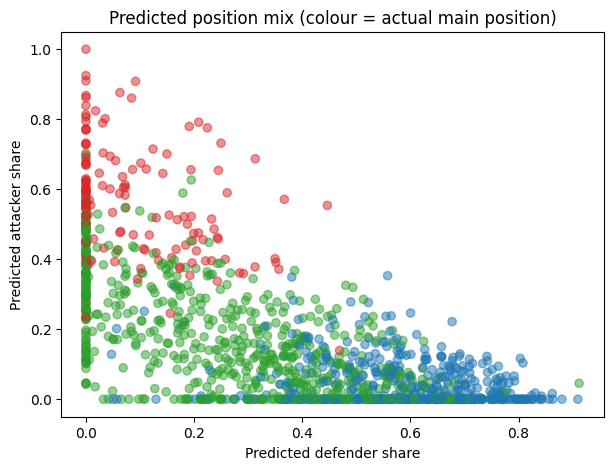

In [13]:
fig,ax = plt.subplots(figsize=(7,5))
cols = {'DF':'tab:blue','MF':'tab:green','FW':'tab:red'}
ax.scatter(P[:,0], P[:,2], c=[cols[t] for t in out.true_top], alpha=.5)
ax.set_xlabel('Predicted defender share'); ax.set_ylabel('Predicted attacker share')
ax.set_title('Predicted position mix (colour = actual main position)'); plt.show()

**Caveats:** linear regression can output values outside 0–1, so predictions are clipped and renormalised afterwards. A multinomial logistic regression would handle this natively. Wingers and wing-backs are the hardest cases, since their per-90 stats overlap with neighbouring roles.

## Added experiment: do advanced WhoScored predictors improve position accuracy?

This section is self-contained and was appended after the existing analysis. It preserves the original experiment and outputs.

**Comparison:** the same verified players, target labels, training splits and estimator, with **12 baseline predictors** versus **23 predictors after adding the 11 advanced statistics**. Success means predicting any officially listed position, matching the scoring above. Single-position and first-listed results are also shown.

**Reporting-period alignment:** the earlier numeric CSV is a 2 November snapshot. Both numeric feature blocks here use current 2026/27 WhoScored totals with identical player/club/league, appearances and minutes. The earlier CSV supplies position labels and eligibility only; its old performance counters are not mixed into the new model. Matching uses exact name aliases, explicit club aliases, nationality and age checks. Players with changed exposure between source captures are excluded.

**Model:** `LinearRegression`. Linear regression fits the three fractional position targets. Negative predictions are clipped and the shares renormalized.

The common baseline is the original linear notebook's core: shots, shots on target, goals, assists, crosses, interceptions, tackles won, the two source foul counts, offsides and yellow cards per 90, plus age. The logistic and neural comparisons use this same core rather than retaining old playing-time proxies that cannot be updated consistently. **The stored results earlier in the notebook are context, not the baseline for this paired experiment.**

In [1]:
# Run this appended section independently; no variables from earlier cells are required.
from pathlib import Path as adv_Path
import sys as adv_sys
import numpy as adv_np
import pandas as adv_pd
import matplotlib.pyplot as adv_plt
from IPython.display import display as adv_display, Markdown as adv_Markdown

adv_project = adv_Path.cwd()
if not (adv_project / 'advanced_position_comparison.py').is_file():
    adv_project = adv_project / 'AI_Football_Project'
if str(adv_project) not in adv_sys.path:
    adv_sys.path.insert(0, str(adv_project))
from advanced_position_comparison import (
    BASE_FEATURES as adv_base_features, ADVANCED_FEATURES as adv_extra_features,
    OUT as adv_output, run_experiment as adv_run_experiment,
    summary_table as adv_summary_table, conclusion as adv_conclusion,
)

adv_model_kind = 'linear'
# Fits are cached only when the source-file and implementation hashes agree.
# Set force=True to recompute all paired fits from the frozen source captures.
adv_data, adv_cohort, adv_result = adv_run_experiment(adv_model_kind, force=False)
print(f"Compared {len(adv_data):,} verified records from {adv_cohort['old_notebook_eligible']:,} originally eligible records.")
print('Baseline predictors:', adv_base_features)
print('Added predictors:', adv_extra_features)

Compared 1,089 verified records from 1,268 originally eligible records.
Baseline predictors: ['Sh_p90', 'SoT_p90', 'Gls_p90', 'Ast_p90', 'Crs_p90', 'Int_p90', 'TklW_p90', 'foulGiven_p90', 'foulCommitted_p90', 'Off_p90', 'CrdY_p90', 'Age']
Added predictors: ['key_passes_p90', 'passes_p90', 'accurate_passes_p90', 'pass_completion_pct', 'long_balls_p90', 'successful_dribbles_p90', 'aerial_duels_won_p90', 'clearances_p90', 'blocks_p90', 'dispossessions_p90', 'poor_controls_p90']


### Results on identical players and splits

All count predictors use exact source minutes: `90 * total / minutes`; pass completion remains a percentage. Five-fold validation is stratified by the first-listed class and grouped by player ID. The additional 20% holdout uses player groups and seed 42. Row expansion, median imputation and numerical scaling happen inside training folds. Neither feature selection nor hyperparameter tuning uses the holdout.

In [2]:
adv_summary = adv_summary_table(adv_result)
adv_formatted_summary = adv_summary.copy()
for adv_column in adv_formatted_summary.columns:
    if adv_column != 'Features':
        adv_formatted_summary[adv_column] = adv_formatted_summary[adv_column].map(lambda value: f'{value:.1%}')
adv_display(adv_formatted_summary)
adv_display(adv_Markdown(adv_conclusion(adv_result)))

,Features,5-fold accuracy,Holdout accuracy,Single-position CV accuracy,First-listed CV accuracy
Predictors,,,,,
Baseline,12,78.1%,83.5%,73.9%,72.3%
Baseline + advanced,23,88.9%,90.4%,86.8%,82.6%


**The advanced predictors improved accuracy in this experiment.** Five-fold accuracy changed from **78.1%** to **88.9%** (**+10.7 percentage points**); the matched holdout changed by **+6.9 points**. This compares the same players, folds, source exposure and model configuration. It is an empirical comparison on this matched cohort, not a claim of future-season performance. Any-listed-position scoring is more permissive for dual-position players; the single-position and first-listed figures above show that distinction.

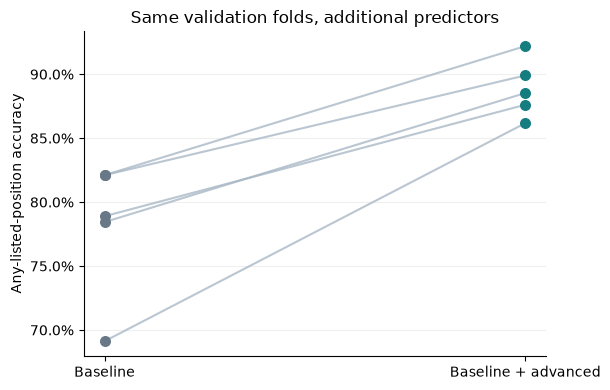

In [3]:
adv_folds = adv_pd.read_csv(adv_output / adv_model_kind / 'fold_scores.csv')
adv_paired = adv_folds.pivot(index='fold', columns='arm', values='any_position_accuracy')
adv_fig, adv_ax = adv_plt.subplots(figsize=(6.2, 4.0))
for adv_fold, adv_row in adv_paired.iterrows():
    adv_ax.plot([0, 1], adv_row[['Baseline', 'Baseline + advanced']], color='#a9b8c6', alpha=.8)
adv_ax.scatter(adv_np.zeros(len(adv_paired)), adv_paired['Baseline'], color='#687887', s=48, zorder=3)
adv_ax.scatter(adv_np.ones(len(adv_paired)), adv_paired['Baseline + advanced'], color='#157c80', s=48, zorder=3)
adv_ax.set_xticks([0, 1], ['Baseline', 'Baseline + advanced'])
adv_ax.set_ylabel('Any-listed-position accuracy')
adv_ax.set_title('Same validation folds, additional predictors')
adv_ax.yaxis.set_major_formatter(adv_plt.matplotlib.ticker.PercentFormatter(1))
adv_ax.grid(axis='y', alpha=.2)
adv_ax.spines[['top', 'right']].set_visible(False)
adv_fig.tight_layout()
adv_fig.savefig(adv_output / adv_model_kind / 'paired_accuracy.png', dpi=160)
adv_plt.show()

### Appendix: cohort changes, model checks and reproduction

The old eligibility rule (`90s >= 3`, no goalkeeper label) identifies the original labelled population. Current source minutes must additionally be at least 270. Ambiguous or unmatched identities, nationality/age conflicts, and inconsistent current exposure are excluded from **both** model arms. This is a matched subset, so these results do not establish accuracy for every player in the original CSV.

MF is the largest first-listed class; no class weighting was introduced, so the comparison changes the predictor set rather than the loss weighting. Any-listed scoring gives dual-position players more valid answers; the stricter columns above help assess the improvement. Position labels come from the earlier official CSV and can lag role changes. IDs, names, clubs, leagues, position columns and WhoScored ratings never enter the predictors.

The implementation and fitted configurations are in `advanced_position_comparison.py`. Exact source hashes and sample exclusions are in [the cohort manifest](advanced_position_results/cohort_manifest.json) and [matching audit](advanced_position_results/cohort_match_audit.csv). Each model folder contains fold scores, out-of-fold predictions and its result/configuration JSON. The fixed folds and holdout overlap as evaluation summaries; they are not independent replications. Results use one specified neural-network seed and do not establish future-season performance.

In [4]:
adv_audit = adv_pd.Series(adv_cohort['match_status_counts'], name='Records').rename_axis('Matching outcome').to_frame()
adv_classes = adv_pd.Series(adv_cohort['primary_class_counts'], name='Records').rename_axis('First-listed class').to_frame()
adv_classes['Share'] = adv_classes['Records'] / len(adv_data)
adv_display(adv_audit)
adv_display(adv_classes.assign(Share=adv_classes.Share.map(lambda value: f'{value:.1%}')))
adv_paired['Change (percentage points)'] = 100 * (adv_paired['Baseline + advanced'] - adv_paired['Baseline'])
adv_display(adv_paired.assign(**{
    'Baseline': adv_paired['Baseline'].map(lambda value: f'{value:.1%}'),
    'Baseline + advanced': adv_paired['Baseline + advanced'].map(lambda value: f'{value:.1%}'),
    'Change (percentage points)': adv_paired['Change (percentage points)'].map(lambda value: f'{value:+.1f}')
}))
adv_warning_count = sum(arm['convergence_warnings'] for arm in adv_result['arms'].values())
if adv_warning_count:
    print(f'Convergence warnings across paired fits: {adv_warning_count}; interpret the neural results with this limitation.')
if adv_model_kind == 'linear':
    print('Cross-validated position-mix MAE:', {name: round(arm['cv']['mix_mae'], 3) for name, arm in adv_result['arms'].items()})
print('Evaluated library versions:', adv_result['versions'])

,Records
Matching outcome,
included,1089
unmatched_identity,89
nationality_conflict,66
current_source_exposure_mismatch,22
fewer_than_270_current_minutes,2


,Records,Share
First-listed class,,
DF,391,35.9%
MF,536,49.2%
FW,162,14.9%


arm,Baseline,Baseline + advanced,Change (percentage points)
fold,,,
1,78.9%,87.6%,+8.7
2,78.4%,88.5%,+10.1
3,82.1%,92.2%,+10.1
4,82.1%,89.9%,+7.8
5,69.1%,86.2%,+17.1


Cross-validated position-mix MAE: {'Baseline': 0.26, 'Baseline + advanced': 0.195}
Evaluated library versions: {'scikit-learn': '1.9.1', 'numpy': '2.5.4', 'pandas': '3.1.1'}
